# Beyond: the reconciliations against reference engines that exist today

**Question:** Does the engine give the numbers that the papers it implements printed, and where it does not, why: how many printed numbers can a reader recompute from the committed inputs, how many agree to the printed digit, and what explains each gap?

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 03, 05 and 06 of this topic (the embedding, the calibration and the low-default bounds)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- recompute with the engine the printed tables of three papers of the ratings and calibration cases (Pluto and Tasche 2005, Tasche 2013, Schuermann and Hanson 2004) and count how many printed numbers agree to the printed digit and by how much the others miss;
- read the gaps that the committed artifacts record for the other two papers (Israel, Rosenthal and Wei; Engelmann) and say what explains each;
- check the engine's p-values on a grid against a quadrature of the Beta density and an exact sum of the binomial terms, and say why a comparison with the SciPy calls the engine itself makes would prove nothing;
- say which reconciliations of the claim belong to another notebook or are not rerun here;
- state the claim BS-2 of the product, the evidence behind it and its limits.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from fractions import Fraction
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import low_default as ldp
from riskvalidation.engines import pd_curve as pc
from riskvalidation.transitions import intervals
from riskvalidation.validation import calibration as cal

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Four committed files, all produced by the pipeline from papers that are derived-only sources (the artifacts carry the printed numbers, rates and profiles, never the papers' own tables of counts):

- `data/derived/C04/published.json`: three papers beside their prints. Israel, Rosenthal and Wei (2001): nine L1 distances, recorded with their recomputation. Schuermann and Hanson (2004), Table 5: the count of obligors and defaults and the printed Wald and Agresti-Coull intervals for BB in 2002. Engelmann (2024): the TTC portfolio and four starting portfolios, recorded with their recomputation.
- `data/derived/C05/sp-2010.json` and `sp-2011.json`: Tasche (2013), Tables 5 to 9 (`outputs.golden`): the printed smoothed curve, the implied profile, the forecast curves of four approaches, the case 3 PDs and the likelihood ratios, with the rates and profiles the engine needs to rebuild them.
- `data/derived/C05/ldp-published.json`: Pluto and Tasche (2005), Tables 1 to 14, 204 printed cells (`outputs.golden.cells`), with the portfolio of the paper's example.

The repository's own reconciliation tests (`tests/test_c04_parity.py`, `tests/test_c04_published.py`, `tests/test_c05.py`) run in the product's test suite, not here. This notebook recomputes with the engine what the committed inputs allow, and reads the rest as recorded.

In [2]:
# Load the committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
published = json.loads((DERIVED / "C04" / "published.json").read_text(encoding="utf-8"))["outputs"]
ldp_doc = json.loads((DERIVED / "C05" / "ldp-published.json").read_text(encoding="utf-8"))["outputs"]
tasche = {}
for year in (2010, 2011):
    document = json.loads((DERIVED / "C05" / f"sp-{year}.json").read_text(encoding="utf-8"))
    tasche[year] = document["outputs"]

## Method

### Step 1: Pluto and Tasche, Tables 1 to 12

A reconciliation recomputes a printed number with the engine and puts the two side by side. A recomputed value agrees with its print when it lies within half a unit of the last printed digit: 2.7245 and 2.7255 both agree with 2.725, because a print does not say how it was rounded. The first paper is Pluto and Tasche (2005), the most prudent estimate of a PD for a portfolio with few or no defaults: three grades of 100, 400 and 300 obligors, with zero defaults or with 0, 2 and 1. Tables 1 to 6 give the independent upper bound at six confidence levels, Tables 7 and 8 the bound with an asset correlation of 12%, and Tables 9 to 12 scale the three grades' bounds to a portfolio target (a multiplier $k$ and the scaled PDs). The next cell recomputes the 168 cells of Tables 1 to 12 with the engine's `most_prudent_pd` and `most_prudent_pd_scaled`.

In [3]:
# Recompute Tables 1 to 12 of Pluto and Tasche with the engine's most prudent estimate
obligors, few, zero = tuple(ldp_doc["obligors"]), tuple(ldp_doc["defaults"]), (0, 0, 0)
gammas, rho = ldp_doc["gammas"], ldp_doc["rho"]
rows = ("pa", "pb", "pc")
scaled_tables = (
    (9, 0.0, "central_tendency"),
    (10, rho, "central_tendency"),
    (11, 0.0, "upper_bound"),
    (12, rho, "upper_bound"),
)
ours_pt = {}
for g in gammas:
    independent_zero = ldp.most_prudent_pd(obligors, zero, g)["pd"]
    independent_few = ldp.most_prudent_pd(obligors, few, g)["pd"]
    correlated_zero = ldp.most_prudent_pd(obligors, zero, g, rho)["pd"]
    correlated_few = ldp.most_prudent_pd(obligors, few, g, rho)["pd"]
    for j, row in enumerate(rows):
        ours_pt[(1 + j, row, g)] = 100 * independent_zero[j]
        ours_pt[(4 + j, row, g)] = 100 * independent_few[j]
        ours_pt[(7, row, g)] = 100 * correlated_zero[j]
        ours_pt[(8, row, g)] = 100 * correlated_few[j]
    for table, r, target in scaled_tables:
        scaled = ldp.most_prudent_pd_scaled(obligors, few, g, r, target=target)
        ours_pt[(table, "k", g)] = scaled["k"]
        for j, row in enumerate(rows):
            ours_pt[(table, row + ",scaled", g)] = 100 * scaled["pd"][j]

first_twelve = [c for c in ldp_doc["golden"]["cells"] if c["table"] <= 12]
printed_pt = {(c["table"], c["row"], c["gamma"]): c["printed"] for c in first_twelve}
print("cells recomputed:", len(ours_pt), "| cells printed in Tables 1 to 12:", len(printed_pt))
print("Table 4, grade A, by level, recomputed:", [round(ours_pt[(4, "pa", g)], 4) for g in gammas])
print("Table 4, grade A, by level, printed:", [printed_pt[(4, "pa", g)] for g in gammas])

cells recomputed: 168 | cells printed in Tables 1 to 12: 168
Table 4, grade A, by level, recomputed: [0.4588, 0.6378, 0.8332, 0.9663, 1.2501, 1.6225]
Table 4, grade A, by level, printed: [0.46, 0.65, 0.83, 0.97, 1.25, 1.62]


The figure draws every recomputed percentage against its printed value on logarithmic axes, coloured by the family of tables, with the diagonal where the two are equal.

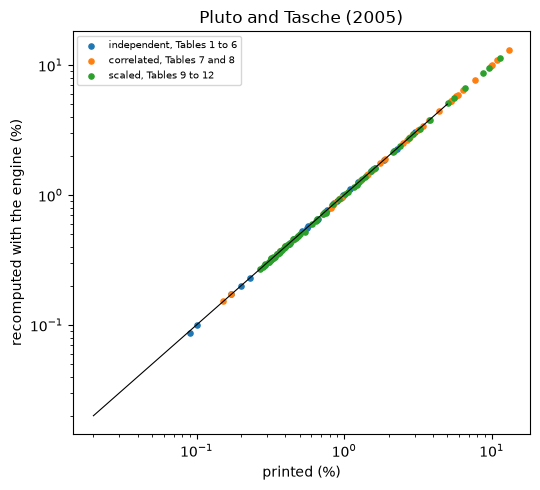

In [4]:
# Draw the recomputed against the printed values of Tables 1 to 12 (the multiplier k aside)
families = (("independent, Tables 1 to 6", range(1, 7)),
            ("correlated, Tables 7 and 8", (7, 8)),
            ("scaled, Tables 9 to 12", range(9, 13)))
fig, ax = plt.subplots(figsize=(5.5, 5))
for label, tables in families:
    keys = [k for k in printed_pt if k[0] in tables and k[1] != "k"]
    ax.scatter([printed_pt[k] for k in keys], [ours_pt[k] for k in keys], s=14, label=label)
ax.plot([0.02, 5], [0.02, 5], color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("printed (%)")
ax.set_ylabel("recomputed with the engine (%)")
ax.set_title("Pluto and Tasche (2005)")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

The points lie on the diagonal across two orders of magnitude, from bounds under 0.1% to bounds above 10%, and for the three families of tables alike. A reading at this scale cannot show the cells that miss by one or two units of the last printed digit, which the tally below counts one by one. It shows that no family of tables is off by a different method or a different convention: the engine is not systematically above or below the paper, and a gap, where there is one, is a matter of the last digit or two.

### Step 2: Tasche (2013), Tables 5 to 9

The second paper is the calibration of a PD curve of notebooks 05 and 09. The committed files hold the printed tables and the rates and profiles the engine needs, so the 2009 curve, the implied default profile and the likelihood ratios of Tables 5, 6 and 9 can be rebuilt from them. The next cell fits the curve by quasi moment matching and reads the three 2009 tables from it.

In [5]:
# Rebuild the 2009 curve of Tasche (2013) by quasi moment matching and the 2009 tables the paper prints
base = tasche[2010]
survival0 = np.array(base["profile0"]) * (1 - np.array(base["default_rate0"]))
survival0 = survival0 / survival0.sum()
start = pc.qmm(base["profile0"], base["pd0"], base["ar0"], survival_profile=list(survival0))
curve0 = np.array(start["pd_curve"])
ours_t = {"table5": 100 * curve0}
ours_t["table6"] = 100 * np.array(pc.implied_default_profile(curve0, base["profile0"]))
ours_t["table9"] = np.array(pc.likelihood_ratio(curve0, start["pd"]))

golden = base["golden"]
printed_t = {"table5": np.array([c["printed"] for c in golden["table5"]])}
printed_t["table6"] = np.array([c["printed"] for c in golden["table6"]])
printed_t["table9"] = np.array([c["printed"] for c in golden["table9_2009"]])
print(f"QMM: alpha {start['alpha']:.4f}, beta {start['beta']:.4f}")
print("Table 5, worst grade, printed and recomputed (%):", printed_t["table5"][-1], round(ours_t["table5"][-1], 4))

QMM: alpha 5.2048, beta 2.1613
Table 5, worst grade, printed and recomputed (%): 48.355 48.3537


The next cell carries the curve to 2010 and 2011 with the four case 1 approaches whose curves Table 7 prints, and with the four case 3 approaches whose forecast PDs Table 8 prints, exactly as in notebook 09.

In [6]:
# Carry the curve to 2010 and 2011: the four curves of Table 7 and the four forecasts of Table 8
ours_t["table7"], ours_t["table8"], printed_t["table7"], printed_t["table8"] = {}, {}, {}, {}
for year, o in tasche.items():
    p1, pd1, pd0 = o["profile1"], o["pd1"], start["pd"]
    dp0 = pc.implied_default_profile(curve0, o["profile0"])
    sv0 = pc.implied_survival_profile(curve0, o["profile0"])
    case1 = {
        "A1-idp": pc.invariant_default_profile(o["default_profile0"], p1, pd1),
        "A2-iar": pc.invariant_accuracy_ratio(p1, pd1, o["ar0"]),
        "A3-spd": pc.scaled_pds(curve0, p1, pd1),
        "A4-slr": pc.scaled_likelihood_ratio(curve0, pd0, p1, pd1),
    }
    ours_t["table7"][year] = {a: 100 * np.array(r["pd_curve"]) for a, r in case1.items()}
    printed_t["table7"][year] = {a: np.array([c["printed"] for c in o["golden"]["table7"][a]]) for a in case1}
    least_squares = pc.invariant_conditional_profiles(dp0, sv0, p1, fit="least_squares")
    least_chi2 = pc.invariant_conditional_profiles(dp0, sv0, p1, fit="least_chi2")
    unchanged = pc.invariant_pd_curve(curve0, p1)["pd_curve"]
    ratio_known = pc.invariant_likelihood_ratio(curve0, pd0, profile_1=p1)
    case3 = [pc.unconditional_pd(unchanged, p1), least_squares["pd"], least_chi2["pd"], ratio_known["pd"]]
    ours_t["table8"][year] = 100 * np.array(case3)
    printed_t["table8"][year] = np.array([c["printed_pct"] for c in o["golden"]["table8"]])
print("Table 8, 2010, printed:", printed_t["table8"][2010], "| recomputed:", np.round(ours_t["table8"][2010], 3))

Table 8, 2010, printed: [4.32 4.8  5.35 5.38] | recomputed: [4.318 4.799 5.347 5.377]


The figure draws the 2009 curve against its printed Table 5 on the left, and the four case 1 curves of 2010 against their printed Table 7 on the right.

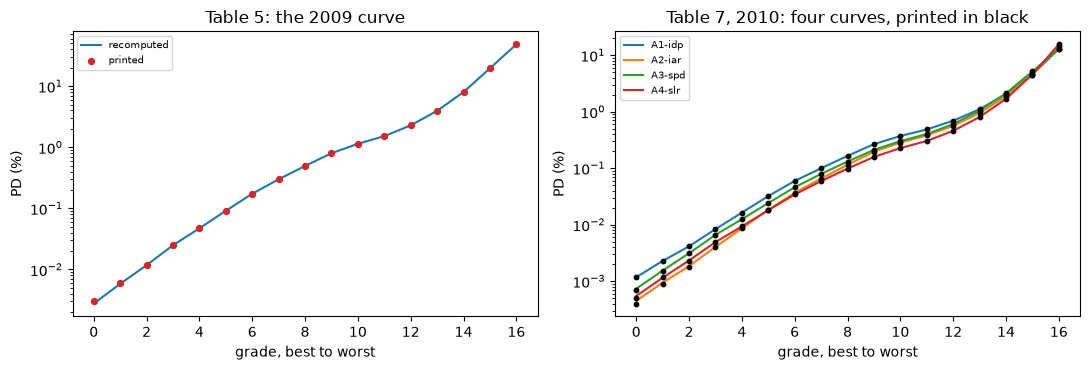

In [7]:
# Draw the 2009 curve and the 2010 curves, recomputed lines against printed markers
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(printed_t["table5"]))
left.plot(x, ours_t["table5"], color="tab:blue", label="recomputed")
left.scatter(x, printed_t["table5"], color="tab:red", s=18, zorder=3, label="printed")
left.set_yscale("log")
left.set_title("Table 5: the 2009 curve")
for a, curve in ours_t["table7"][2010].items():
    right.plot(x, curve, label=a)
    right.scatter(x, printed_t["table7"][2010][a], s=10, color="black", zorder=3)
right.set_yscale("log")
right.set_title("Table 7, 2010: four curves, printed in black")
for ax in (left, right):
    ax.set_xlabel("grade, best to worst")
    ax.set_ylabel("PD (%)")
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

The recomputed curves run through the printed points over four orders of magnitude, in the 2009 curve and in each of the four forecast curves of 2010, so the engine's quasi moment matching and its four approaches give the paper's numbers. At this scale a miss of one unit of the fourth decimal in a percentage cannot show, and the tally below counts those. The figure also hides the PD floor and the grades with the tiniest PDs, where the print has too few significant digits to compare: the right panel stops being informative below about 0.001%.

### Step 3: Schuermann and Hanson (2004), Table 5

The third paper prints the Wald and Agresti-Coull 95% intervals of the BB grade in 2002, with 531 obligors, at three values of the default correlation (0, 0.01 and 0.02), each as a lower bound, an upper bound and a length. The table does not print the number of defaults; the artifact records the only count, 15, whose independent Wald lower bound prints as the table's. The next cell runs the engine's `pd_wald` and `pd_agresti_coull` at each correlation, where the correlation enters through the effective sample size of the paper's equation (3.4).

In [8]:
# Recompute the six intervals of Table 5 of Schuermann and Hanson with the engine
sr = published["sr190"]
ours_sr, printed_sr = [], []
for row in sr["rows"]:
    settings = {"level": 0.95, "rho": row["rho"]}
    if row["interval"] == "wald":
        result = intervals.pd_wald(sr["defaults"], sr["n"], **settings)
    else:
        result = intervals.pd_agresti_coull(sr["defaults"], sr["n"], **settings)
    ours_sr += [float(result[key]) for key in ("lower", "upper", "length")]
    printed_sr += row["printed"]
    print(f"{row['interval']:14s} rho {row['rho']:.2f}: printed {row['printed']}")
    print(f"{'':14s} {'':8s}  recomputed {np.round(ours_sr[-3:], 6)}")

wald           rho 0.00: printed [0.014156, 0.042341, 0.028184]
                         recomputed [0.014156 0.042341 0.028184]
wald           rho 0.01: printed [0.0, 0.06362, 0.06362]
                         recomputed [0.      0.06362 0.06362]
wald           rho 0.02: printed [0.0, 0.076245, 0.076245]
                         recomputed [0.       0.076245 0.076245]
agresti_coull  rho 0.00: printed [0.016803, 0.046471, 0.029668]
                         recomputed [0.016803 0.046471 0.029668]
agresti_coull  rho 0.01: printed [0.003825, 0.0938, 0.089975]
                         recomputed [0.003825 0.0938   0.089975]
agresti_coull  rho 0.02: printed [0.0, 0.133256, 0.133256]
                         recomputed [0.       0.133256 0.133256]


Each printed triple is the recomputed one to the six decimals printed. The only inputs are the 531 obligors and 15 defaults, so the intervals are a direct test of the formulas of the paper's section 3, including the design-effect correction at positive correlation, which widens the interval as the correlation grows. These are the bounds of the BB grade, a single table of the paper; what the agreement does not show is that the engine reproduces the paper's other estimates, such as the ones from duration data.

### Step 4: the p-values of the Jeffreys and binomial tests, against two independent recomputations

Many engine tests are a tail probability of a standard distribution: the Jeffreys test is a Beta distribution function and the binomial test a binomial tail. The engine computes them with `scipy.stats.beta.cdf(pd, d + 1/2, n - d + 1/2)` and `scipy.stats.binom.sf(d - 1, n, pd)`. A comparison with those same two calls would give a difference of 0 by construction: it would show that the parameterisation and the tail convention are the ones written, and it would pass even if SciPy were wrong. The reconciliation here uses two routes that call neither function:

- the Jeffreys p-value as the integral of the Beta density from 0 to the applied PD. The substitution $x = p\,u^2$ turns the density, singular at 0, into the smooth integrand $2\,p^{a} u^{2d} (1 - p u^2)^{b-1}$, with $a = d + \tfrac12$ and $b = n - d + \tfrac12$, which a 400-point Gauss-Legendre rule integrates to machine precision, divided by the Beta function written with `math.lgamma`;
- the binomial p-value as one minus the exact sum of the first $d$ binomial terms, in rational arithmetic (`fractions.Fraction` of the float PD and `math.comb`), rounded once at the end.

The next cell calls the engine's two tests on a grid of 36 cases (obligors, defaults, applied PD) and keeps the differences to each route.

In [9]:
# Compare the engine's Jeffreys and binomial p-values with two routes that call neither of its SciPy functions
grid = [(n, d, p) for n in (50, 500, 5000) for d in (0, 1, 3, 10) for p in (0.001, 0.01, 0.05)]
nodes, weights = np.polynomial.legendre.leggauss(400)
u, w = (nodes + 1) / 2, weights / 2
jeffreys_gap, binomial_gap = [], []
for n, d, p in grid:
    a, b = d + 0.5, n - d + 0.5
    integral = 2 * p**a * np.sum(w * u ** (2 * d) * (1 - p * u**2) ** (b - 1))
    jeffreys_route = integral / math.exp(math.lgamma(a) + math.lgamma(b) - math.lgamma(a + b))
    q = Fraction(p)
    binomial_route = float(1 - sum(math.comb(n, k) * q**k * (1 - q) ** (n - k) for k in range(d)))
    jeffreys_gap.append(abs(cal.pd_jeffreys(n=n, d=d, pd=p).p_value - jeffreys_route))
    binomial_gap.append(abs(cal.pd_binomial(n=n, d=d, pd=p).p_value - binomial_route))
print("cases:", len(grid))
print("Jeffreys: largest difference to the quadrature of the Beta density:", f"{max(jeffreys_gap):.1e}")
print("binomial: largest difference to the exact sum of the binomial terms:", f"{max(binomial_gap):.1e}")

cases: 36
Jeffreys: largest difference to the quadrature of the Beta density: 5.7e-12
binomial: largest difference to the exact sum of the binomial terms: 5.6e-16


The figure draws the 72 differences on a logarithmic axis against a tolerance of 1e-9, the Jeffreys ones against the quadrature and the binomial ones against the exact sum.

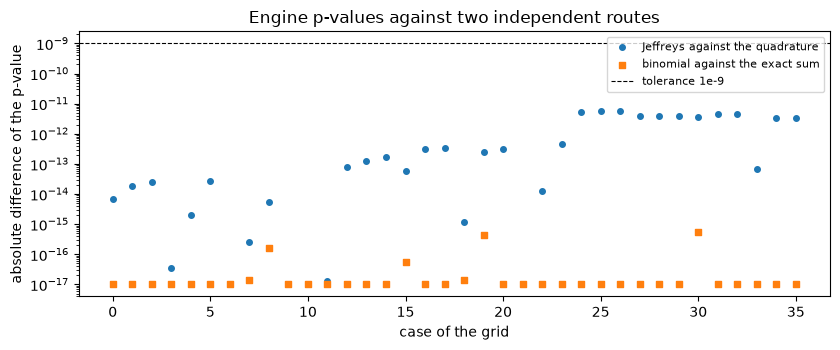

In [10]:
# Draw the differences of the engine's p-values to the two independent routes
fig, ax = plt.subplots(figsize=(8.5, 3.6))
floor = 1e-17
label_j = "Jeffreys against the quadrature"
label_b = "binomial against the exact sum"
ax.scatter(range(len(grid)), np.maximum(jeffreys_gap, floor), s=16, label=label_j)
ax.scatter(range(len(grid)), np.maximum(binomial_gap, floor), s=16, marker="s", label=label_b)
ax.axhline(1e-9, color="black", linestyle="--", linewidth=0.8, label="tolerance 1e-9")
ax.set_yscale("log")
ax.set_xlabel("case of the grid")
ax.set_ylabel("absolute difference of the p-value")
ax.set_title("Engine p-values against two independent routes")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Every difference sits far below the tolerance: the Jeffreys p-values agree with the quadrature of the Beta density to about 1e-11 and the binomial ones with the exact sum to the limit of floating-point arithmetic, 1e-16 and below. Points drawn at the bottom of the axis are exact zeros, clipped for the logarithmic scale. The agreement holds across sample sizes from 50 to 5,000, zero to ten defaults and PDs from 0.1% to 5%, where the Beta and binomial computations are most delicate. The figure says nothing about SciPy's other distributions or the engine's tests that are not a standard tail.

### Step 5: the tally, and the gaps with what explains them

The tally counts, for every table recomputed above, how many printed numbers agree to the printed digit (within half a unit of the last printed digit) and the largest gap in the unit of the print. The last three sources are read as the artifacts record them, because their inputs are not committed: Israel, Rosenthal and Wei's agency matrices and Engelmann's matrix are papers' tables that the licence class keeps out of the repository, and Tables 13 and 14 of Pluto and Tasche are Monte Carlo runs of 100,000 samples that this notebook does not repeat. The cell is the notebook's one reproduction check.

In [11]:
# Tally the printed numbers by source: how many, how many agree to the printed digit, the largest gap
keys = sorted(printed_pt, key=str)
compared = [
    ("Pluto and Tasche (2005), Tables 1 to 12", [ours_pt[k] for k in keys],
     [printed_pt[k] for k in keys], 2, "pp"),
    ("Tasche (2013), Table 5", ours_t["table5"], printed_t["table5"], 3, "pp"),
    ("Tasche (2013), Table 6", ours_t["table6"], printed_t["table6"], 4, "pp"),
    ("Tasche (2013), Table 9, 2009", ours_t["table9"], printed_t["table9"], 2, "ratio"),
    ("Schuermann and Hanson (2004), Table 5", ours_sr, printed_sr, 6, "prob."),
]
for year in tasche:
    flat_ours = np.concatenate([ours_t["table7"][year][a] for a in ours_t["table7"][year]])
    flat_printed = np.concatenate([printed_t["table7"][year][a] for a in printed_t["table7"][year]])
    compared.append((f"Tasche (2013), Table 7, {year}", flat_ours, flat_printed, 4, "pp"))
    compared.append((f"Tasche (2013), Table 8, {year}", ours_t["table8"][year], printed_t["table8"][year], 2, "pp"))
tally, gaps = [], {}
for name, ours, printed, decimals, unit in compared:
    gap = np.array(ours) - np.array(printed)
    gaps[name] = gap
    agree = int(np.sum(np.abs(gap) <= 0.5 * 10.0**-decimals + 1e-9))
    tally.append((name, gap.size, agree, float(np.abs(gap).max()), unit, "recomputed"))
for row in tally:
    print(f"{row[0]:42s}{row[1]:6d}{row[2]:6d}{row[3]:10.4f}  {row[4]}")

Pluto and Tasche (2005), Tables 1 to 12      168   125    0.0951  pp
Tasche (2013), Table 5                        17    15    0.0013  pp
Tasche (2013), Table 6                        17     8    0.0013  pp
Tasche (2013), Table 9, 2009                  17    10    0.3579  ratio
Schuermann and Hanson (2004), Table 5         18    18    0.0000  prob.
Tasche (2013), Table 7, 2010                  68    54    0.0005  pp
Tasche (2013), Table 8, 2010                   4     4    0.0035  pp
Tasche (2013), Table 7, 2011                  68    52    0.0004  pp
Tasche (2013), Table 8, 2011                   4     3    0.0057  pp


The recomputed sources are counted. The next cell adds the three sources read as recorded, from the committed artifacts, with the same rule of agreement, and prints the totals.

In [12]:
# Add the sources read as recorded: Israel et al., Engelmann and Tables 13 and 14 of Pluto and Tasche
irw = published["irw"]["rows"]
irw_gap = max(abs(r["printed"] - r["recomputed"]) for r in irw)
tally.append(("Israel et al. (2001), L1 distances", len(irw), sum(r["agrees"] for r in irw), irw_gap, "L1", "read"))
eng = published["engelmann"]
checks = list(zip(eng["w_ttc"]["printed"], eng["w_ttc"]["recomputed"], eng["w_ttc"]["decimals"]))
checks.append((eng["ttc_pd"]["printed"], eng["ttc_pd"]["recomputed"], eng["ttc_pd"]["decimals"]))
starts = [q["pd0"] for q in eng["portfolios"] if q["pd0"]["check"] == "printed digits"]
checks += [(s0["printed"], s0["recomputed"], s0["decimals"]) for s0 in starts]
agree = sum(abs(r - p) <= 0.5 * 10.0**-d + 1e-9 for p, r, d in checks)
eng_gap = max(abs(r - p) for p, r, _ in checks)
tally.append(("Engelmann (2024), TTC portfolio and PDs", len(checks), int(agree), eng_gap, "prob.", "read"))
late = [c["gap"] for c in ldp_doc["golden"]["cells"] if c["table"] >= 13]
late_name = "Pluto and Tasche (2005), Tables 13 and 14"
tally.append((late_name, len(late), sum(g == 0 for g in late), max(abs(g) for g in late), "pp", "read"))
total, agree_total = sum(r[1] for r in tally), sum(r[2] for r in tally)
recomputed_n = sum(r[1] for r in tally if r[5] == "recomputed")
print(f"printed numbers compared: {total} | agree to the printed digit: {agree_total}")
print(f"recomputed here: {recomputed_n}, read as recorded: {total - recomputed_n}")

printed numbers compared: 438 | agree to the printed digit: 313
recomputed here: 381, read as recorded: 57


The gaps follow. Each miss has an explanation in the artifact or in the pipeline's reading of the paper: the cell prints the cells of Pluto and Tasche's Tables 1 to 12 that differ from the print by more than one unit of the last digit, the p-values of Tasche's Table 7 beside the artifact's own Monte Carlo, and the notes the artifact keeps for the paper's irregular cells.

In [13]:
# The cells that miss by more than one unit of the last digit, and the notes the artifact keeps
pt_gap = gaps[compared[0][0]]
head = "table"
for k, g in zip(keys, pt_gap):
    if abs(g) > 0.0105:
        values = f"printed {printed_pt[k]:6.2f} | recomputed {ours_pt[k]:8.4f}"
        print(f"{head} {k[0]:2d} {k[1]:10s} gamma {k[2]:5.3f} | {values}")
for year in tasche:
    for row in tasche[year]["golden"]["table7_p_values"]:
        printed_p, artifact_p = row["printed_pct"], row["ours_pct"]
        print(f"Tasche {year} p-value {row['approach']}: printed {printed_p:5.1f}% | artifact {artifact_p:5.2f}%")
for table, note in ldp_doc["golden"]["notes"].items():
    print(f"Pluto and Tasche, Table {table}: {note}")
miss = [r for r in irw if not r["agrees"]][0]
print("Israel et al.:", miss["matrix"], miss["method"], miss["printed"], round(miss["recomputed"], 6))
print("Israel et al., from the printed generator:", published["irw"]["jlt_from_printed_generator"])

table 11 k          gamma 0.750 | printed   0.83 | recomputed   0.8180
table 11 pa,scaled  gamma 0.750 | printed   0.54 | recomputed   0.5217
table 11 pb,scaled  gamma 0.750 | printed   0.61 | recomputed   0.5962
table 11 pc,scaled  gamma 0.750 | printed   0.75 | recomputed   0.7321
table 11 pc,scaled  gamma 0.950 | printed   1.22 | recomputed   1.2032
table 12 pa,scaled  gamma 0.500 | printed   0.64 | recomputed   0.6293
table 12 pa,scaled  gamma 0.950 | printed   2.95 | recomputed   2.9384
table 12 pb,scaled  gamma 0.500 | printed   0.72 | recomputed   0.7090
table 12 pb,scaled  gamma 0.999 | printed   9.54 | recomputed   9.4449
table 12 pc,scaled  gamma 0.900 | printed   2.76 | recomputed   2.7466
table  4 pa         gamma 0.750 | printed   0.65 | recomputed   0.6378
Tasche 2010 p-value A1-idp: printed   4.6% | artifact  4.58%
Tasche 2010 p-value A2-iar: printed   8.0% | artifact  7.91%
Tasche 2010 p-value A3-spd: printed   4.0% | artifact  4.25%
Tasche 2010 p-value A4-slr: printed 

## State of the art

### What the practice does, and what is not rerun here

Toolkits for credit-risk validation ship the estimators and tests and leave the reconciliation to the user: the user decides whether the implementation reproduces the paper it cites. The research (dossier 05) lists ORE and QuantLib as reference engines whose numbers may be claimed only within the reconciliations actually run. Two reconciliations of the claim are **not rerun in this notebook**:

- **The Hull-White exposure against ORE.** It exists and it is claimed: notebook 08 of the counterparty topic reconciles the Hull-White exposure of a single swap and of a four-swap netting set against ORE 1.8.17.0 within two combined Monte Carlo standard errors at all 33 report dates, with the EEPE and the CVA, and reports the collateralised and initial-margin variants as gaps. It belongs to that topic, and its numbers are read there.
- **The equality of the cohort estimator with the `transitionMatrix` library.** The engine's own tests carry it (RV-415, announced in the engine's release notes of 0.8.0): `pooled_cohort` and `cohort` are compared element-wise with the package's cohort estimator within 1e-12 on a seeded panel with withdrawals, and the differences of convention are pinned as findings. The tests run where the optional `transitions` extra of the wheel, which pins `transitionMatrix` 0.5.1, is installed. That package is not among the pins of this notebook, so this notebook does not rerun the equality and the claim BS-2 does not count it as a result of this notebook. What is run here is the engine against the printed tables of the papers above, and the p-values against two independent routes.

## Beyond the state of the art

### Claim BS-2: the reconciliations against reference engines that exist today

**What Contraste adds.** The engine's tests and estimators are held to independent implementations and to the printed digits of the papers, and the gap is reported. The reconciliations that exist are the ones claimed: the printed tables and papers recomputed beside their prints, the p-values of the Jeffreys and binomial tests against two independent recomputations, and the Hull-White exposure against ORE that notebook 08 of the counterparty topic demonstrates. Not claimed here: the collateralised and initial-margin variants against ORE, which topic 08 reports as gaps, and the equality with the transition-matrix cohort estimator, which the engine tests (RV-415) and no notebook of Contraste reruns. The next cell lists the statements of the claim that this notebook can read, with the values computed above.

In [14]:
# Each statement of the claim with the value this notebook computed
pluto = tally[0]
within = int(sum(x < 1e-9 for x in jeffreys_gap + binomial_gap))
statements = [
    ("printed numbers compared, five papers", total),
    ("of them, agreeing to the printed digit", agree_total),
    ("Pluto and Tasche cells recomputed, Tables 1 to 12", pluto[1]),
    ("of them, agreeing to the digit", pluto[2]),
    ("p-values compared with an independent route", 2 * len(grid)),
    ("of them, within 1e-9", within),
]
for text, value in statements:
    print(f"{value:6d}  {text}")
print("not rerun here: Hull-White / ORE (topic 08) | cohort / transitionMatrix (RV-415)")

   438  printed numbers compared, five papers
   313  of them, agreeing to the printed digit
   168  Pluto and Tasche cells recomputed, Tables 1 to 12
   125  of them, agreeing to the digit
    72  p-values compared with an independent route
    72  of them, within 1e-9
not rerun here: Hull-White / ORE (topic 08) | cohort / transitionMatrix (RV-415)


**Limits of the claim.** It counts reconciliations that exist and reports the gaps; it does not say that every number of the engine is reconciled. The ratings and calibration cases are reconciled to five papers and to two independent computations of standard tails; the other cases rest on their own references (the topic notebooks name them). A gap that is explained, such as the print of the Israel et al. matrix, is still a gap and is listed. The comparison is with the print of the paper; where a paper's own arithmetic differs from its text, the engine follows the text, and the artifact says so. Three of the five papers are recomputed here from rates and profiles; the other two are counted as the artifacts record them, because their inputs are tables that the licence keeps out of the repository.

The figure draws, for each source, the share of the printed numbers that agree to the printed digit, with the sources recomputed in this notebook apart from those read as recorded.

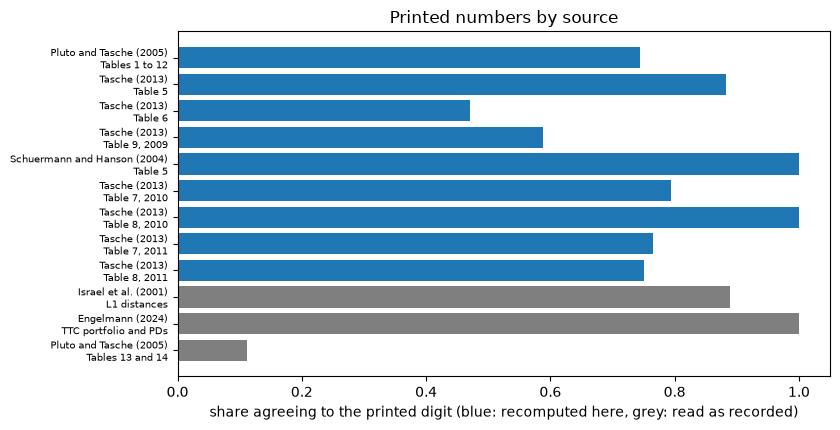

In [15]:
# Draw the share of printed numbers that agree to the printed digit, by source
labels = [r[0].replace(", ", "\n", 1) for r in tally]
shares = [r[2] / r[1] for r in tally]
colours = ["tab:blue" if r[5] == "recomputed" else "tab:grey" for r in tally]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.barh(range(len(tally)), shares, color=colours)
ax.set_yticks(range(len(tally)))
ax.set_yticklabels(labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("share agreeing to the printed digit (blue: recomputed here, grey: read as recorded)")
ax.set_title("Printed numbers by source")
fig.tight_layout()
plt.show()

Schuermann and Hanson's table and Engelmann's numbers reach a full share, and Tasche's Table 8 is at or near it. The shorter bars are the tables printed with the most digits or computed by simulation: Tasche's Tables 6 and 7, where the engine misses the print by one or two units of the last digit and never by more than 0.0013 points; Table 9, whose likelihood ratios come from the paper's own quasi moment matching solver, with an offset of about 0.2%; and Pluto and Tasche's multi-period Tables 13 and 14, Monte Carlo prints that lie 1% to 5% above the engine's quadrature at 99% and 99.9%, where 4 of 36 cells agree. A bar below one is a number that the engine reproduces to within a unit or two of the last digit, as the largest gaps printed above show, and not an error of method. Equally, a bar at one is not proof of correctness: it says that the engine and the paper agree, and a paper may differ from its own text.

## Results

**Answer:** Mostly yes, and each miss is small and has a recorded cause. Of the 438 printed numbers that the ratings and calibration cases put beside the engine, 313 agree to the printed digit; 381 are recomputed in this notebook from the committed rates and profiles and 57 are read as the artifacts record them. The largest miss in Tables 1 to 12 of Pluto and Tasche is 0.0951 percentage points (Table 12, grade B at 99.9%, printed 9.54 against 9.4449), in Tasche's Tables 5, 6, 7 and 8 at most 0.0057 percentage points, and in Table 9 the likelihood ratios differ by up to 0.3579 because the paper's own solver carries an offset. Schuermann and Hanson's 18 numbers all agree, and the engine's Jeffreys and binomial p-values equal two independent computations within 5.7e-12 and 5.6e-16.

- **What exists.** Recomputed here: Pluto and Tasche's Tables 1 to 12, 125 of 168 cells (largest gap 0.0951 points); Tasche's Table 5, 15 of 17 (0.0013) and Table 6, 8 of 17 (0.0013); his Table 7, 54 of 68 in 2010 and 52 of 68 in 2011 (0.0005 and 0.0004), Table 8, 4 of 4 and 3 of 4 (0.0035 and 0.0057) and Table 9, 10 of 17; Schuermann and Hanson's Table 5, 18 of 18, to the six decimals printed. Read as recorded: Israel, Rosenthal and Wei, 8 of 9 distances (largest gap 0.0004 in the L1 distance); Engelmann, 12 of 12 numbers; and Pluto and Tasche's multi-period Tables 13 and 14, 4 of 36 cells to the digit.
- **The gaps are recorded and explained.** The one Israel et al. distance that disagrees prints 0.1169 where the matrix gives 0.1165, and equals 0.1169 from the paper's printed generator. Tasche's printed p-values (4.6, 8.0, 4.0 and 11.3% in 2010; 78.5, 89.4, 36.6 and 82.2% in 2011) lie within 0.36 points of the artifact's, from 100,000 draws against the paper's 2,000. Of the 168 cells of Pluto and Tasche's Tables 1 to 12, 43 differ from the print by one unit of the last digit or more, and 11 by more than one unit, listed above: Table 4 at 75% (the print is the bound at 76.3%), and Tables 11 and 12, which scale the printed and rounded bounds of Tables 4 and 8; B at 99.9% prints 9.54 against 9.44.
- **Independent recomputations.** On a grid of 36 cases the engine's Jeffreys p-values equal the Beta distribution function computed by quadrature of its density (largest difference 5.7e-12) and its binomial p-values equal the exact rational sum of the binomial terms (5.6e-16): 72 of 72 within 1e-9. The comparison with SciPy's own calls is dropped, because the engine makes those calls and the difference could only be 0.
- **Read elsewhere or not rerun here.** The Hull-White exposure against ORE is demonstrated in notebook 08 of the counterparty topic and read there. The equality of the cohort estimator with `transitionMatrix` is an engine test (RV-415) that this notebook does not rerun, so it is reported and not counted.
- **The claim.** The six statements of BS-2 that this notebook can read are listed with their values.

What this notebook does not show: the reconciliations of the other cases (the notebooks of their topics name their references), or the inputs of Israel, Rosenthal and Wei and of Engelmann, which the licence keeps out of the repository.

## Summary

- The engine recomputes the printed tables of three papers from the committed rates and profiles, and agrees to the printed digit on most of the numbers; the misses are one or two units of the last digit, each with an explanation.
- Two more papers are counted as the artifacts record them, and their gaps are listed with their causes.
- A check against the very call the engine makes proves only the parameterisation; the p-values are held to a quadrature and to an exact sum instead.
- The Hull-White reconciliation against ORE is demonstrated in topic 08; the equality with `transitionMatrix` is an engine test that this notebook reports and does not rerun.
- The claim BS-2 counts what exists; it does not say that every number of the engine is reconciled.

**What to try next.** Recompute Table 4 of Pluto and Tasche at another confidence level and compare it with the exact bound; then read the notebooks of the next topic.

## References

- Israel, R. B., Rosenthal, J. S. and Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, with applications to credit ratings, Mathematical Finance 11(2). https://doi.org/10.1111/1467-9965.00114
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, Table 5. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), Tables 5 to 9. https://doi.org/10.21314/jcr.2013.169
- Pluto, K. and Tasche, D. (2005), Estimating probabilities of default for low default portfolios, arXiv cond-mat/0411699, Tables 1 to 14. https://arxiv.org/abs/cond-mat/0411699
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892, section 4.
- SciPy `scipy.stats.beta` and `scipy.stats.binom`, at the pinned version of notebooks/requirements.txt, and NumPy `numpy.polynomial.legendre`, and the `math` and `fractions` modules of the Python standard library.